# Sensitivity analysis: required fuel vs. assumptions and airfoils

1. **One-at-a-time sweep:** each assumption is varied over a plausible range while **all other inputs stay fixed at `base.json`**.
2. **Airfoil comparison:** the same aircraft with different airfoil data swapped in.

Every case runs the full pipeline (`run_pipeline`): it sizes the plane, gives the wing to the OpenVSP model and feeds the parasite drag back until it settles, so a case that changes the wing area also gets its own drag. The main output is the **required fuel mass** for mission range + reserve; a second plot shows the **range** with the fuel fixed. Cases where the mission can't be reached (or the iteration doesn't converge) are left out of the curves.

Each OpenVSP run takes ~1.3 s and a case needs 2–3, so the sweeps take several minutes. Lower `N_POINTS` for a quick look.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import ardea_sizer as az
from ardea_sizer.pipeline import run_pipeline
from ardea_sizer.physics import (
    get_alpha_cruise, get_c_l_alpha_3d, get_c_l_cruise, get_c_l_max_3d,
    get_dynamic_pressure, get_isa_density, get_total_mass,
)
from ardea_sizer._constants import FIELD_ALTITUDE

base = az.load("base.json")
FUEL_MASS = base.masses.fuel.mass  # kg, tank from base.json; fixed for the range plot


def try_pipeline(b, **kwargs):
    """Converged plane of `run_pipeline`, or None where the mission can't be reached / it doesn't converge."""
    try:
        return run_pipeline(b, verbose=False, **kwargs)[0]
    except (ValueError, RuntimeError):
        return None


def get_fuel_kg(b, **kwargs) -> float:
    plane = try_pipeline(b, **kwargs)
    return np.nan if plane is None else float(plane.fuel_mass)


def get_cruise_thrust(b, plane) -> tuple[float, float]:
    """(required, available) cruise thrust [N]: at MTOW, engine power lapsed to cruise altitude."""
    v, eta = b.mission.cruise_speed, b.engine.prop_eff
    sigma = get_isa_density(altitude=FIELD_ALTITUDE + 120) / get_isa_density(altitude=0)
    return float(plane.power_req) * eta / v, b.engine.p_max * 1000 * sigma * eta / v


# baseline; `base` then holds the OpenVSP drag, so every sweep starts close to converged
plane_base, base = run_pipeline(base, verbose=False)
fuel_base = float(plane_base.fuel_mass)
thrust_base, thrust_avail_base = get_cruise_thrust(base, plane_base)
range_base = float(run_pipeline(base, fuel_mass=FUEL_MASS, verbose=False)[0].range) / 1000
print(f"Mission: {base.mission.range / 1000:.0f} km + {base.mission.reserve / 1000:.0f} km reserve   "
      f"baseline fuel: {fuel_base:.2f} kg   cruise thrust: {thrust_base:.1f} N of {thrust_avail_base:.1f} N available")
print(f"OpenVSP drag: c_d_0_wing {base.assumptions.c_d_0_wing:.5f}, f_fixed {base.assumptions.f_fixed:.5f} m², "
      f"CD0 {float(plane_base.c_d_0):.4f} at S = {float(plane_base.wing_area):.3f} m²")
print(f"Range with a fixed {FUEL_MASS:.2f} kg of fuel: {range_base:.0f} km")

Mission: 1000 km + 50 km reserve   baseline fuel: 7.51 kg   cruise thrust: 43.3 N of 42.4 N available
OpenVSP drag: c_d_0_wing 0.00854, f_fixed 0.00610 m², CD0 0.0209 at S = 0.493 m²
Range with a fixed 5.00 kg of fuel: 739 km


In [2]:
# chart style
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = "#2a78d6"



def style(ax):
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

## 1. Sweep definitions

`dotted path in base.json: (label, min, max)`. Add engine or mission values the same way, e.g. `"engine.prop_eff"`.

`c_d_0_wing` and `f_fixed` are not swept: OpenVSP computes them for every case. To study the drag, change the drag settings in the `.vsp3` (form factors, excrescences). Note: OpenVSP uses the flow conditions saved in the `.vsp3` (83.33 m/s, 560 m), so the cruise-speed sweep doesn't change the Reynolds number there.

Airfoil inputs ($c_{l,max}$, $c_{l,\alpha}$, $\alpha_{0L}$) are compared in section 2 instead of swept here.

Where the cruise thrust required (at MTOW) exceeds what $P_{max}$ delivers at cruise altitude, the design can't fly that case: those parts of a curve are shaded grey.

In [3]:
SWEEPS = {
    "mission.cruise_speed":           ("Cruise speed [m/s]",            60.0,  90.0),
    "mission.stall_speed":            ("Stall speed [m/s]",             15.0,  28.0),
    "assumptions.delta_c_l_flap":     ("$\\Delta C_{L}$ flap",          0.0,   1.0),
    "assumptions.oswald_eff":         ("Oswald efficiency $e$",         0.6,   0.95),
    "assumptions.wing_ar":            ("Aspect ratio $AR$",             3.0,   12.0),
}
N_POINTS = 11  # every point runs OpenVSP 2–3 times per plot


def get_value(b, path):
    obj = b
    for part in path.split("."):
        obj = getattr(obj, part)
    return obj


results = {}
for path, (label, lo, hi) in SWEEPS.items():
    values = np.linspace(lo, hi, N_POINTS)
    bases = [base.with_(**{path: v}) for v in values]
    planes = [try_pipeline(b) for b in bases]
    thrust = np.array([get_cruise_thrust(b, p) if p is not None else (np.nan, np.nan) for b, p in zip(bases, planes)])
    fixed = [try_pipeline(b, fuel_mass=FUEL_MASS) for b in bases]
    thrust_fixed = np.array([get_cruise_thrust(b, p) if p is not None else (np.nan, np.nan) for b, p in zip(bases, fixed)])
    results[path] = pd.DataFrame({
        "value": values,
        "fuel_kg": [np.nan if p is None else float(p.fuel_mass) for p in planes],
        "thrust_req_n": thrust[:, 0],
        "thrust_avail_n": thrust[:, 1],
        "power_ok": thrust[:, 0] <= thrust[:, 1],  # nan (not reachable) -> False
        "c_d_0": [np.nan if p is None else float(p.c_d_0) for p in planes],
        "range_km": [np.nan if p is None else float(p.range) / 1000 for p in fixed],  # fuel fixed at FUEL_MASS
        "range_power_ok": thrust_fixed[:, 0] <= thrust_fixed[:, 1],
    })
    print(f"{label}: done")

pd.DataFrame(
    {
        "baseline": [get_value(base, p) for p in SWEEPS],
        "fuel at min [kg]": [results[p].fuel_kg.iloc[0] for p in SWEEPS],
        "fuel at max [kg]": [results[p].fuel_kg.iloc[-1] for p in SWEEPS],
    },
    index=[label for label, *_ in SWEEPS.values()],
).round(3)

Cruise speed [m/s]: done
Stall speed [m/s]: done
$\Delta C_{L}$ flap: done
Oswald efficiency $e$: done
Aspect ratio $AR$: done


,baseline,fuel at min [kg],fuel at max [kg]
Cruise speed [m/s],83.33,3.900,8.948
Stall speed [m/s],20.00,11.154,5.895
$\Delta C_{L}$ flap,0.50,9.117,6.727
Oswald efficiency $e$,0.80,7.588,7.466
Aspect ratio $AR$,5.00,7.397,7.989


### Required fuel vs. each assumption

Same y-axis on every panel so the slopes are directly comparable. Dot = baseline from `base.json`, grey band = not enough engine power (or mission not reachable).

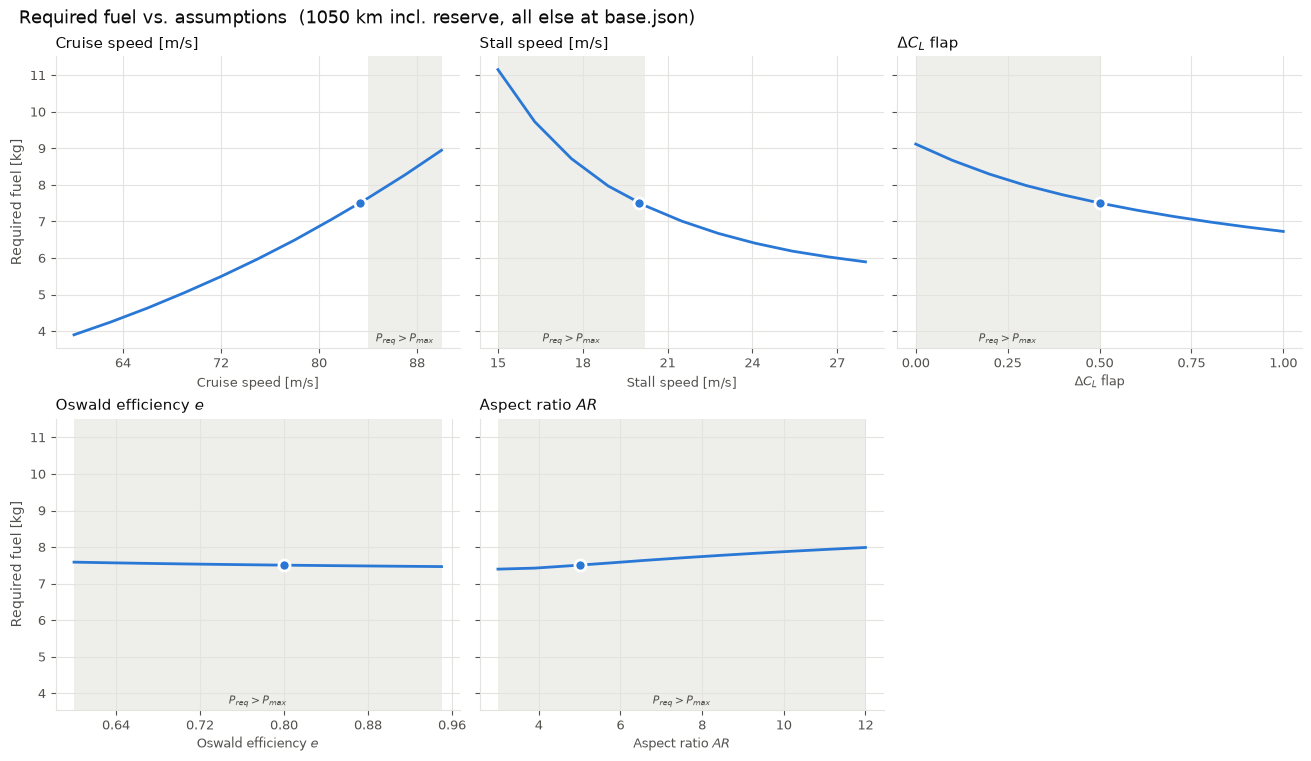

In [4]:
n_cols = 3
n_rows = -(-len(SWEEPS) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 3.75 * n_rows), sharey=True, constrained_layout=True)

for ax, (path, (label, *_)) in zip(axes.flat, SWEEPS.items()):
    df = results[path]

    bad = df.value[~df.power_ok]
    if len(bad):
        ax.axvspan(bad.min(), bad.max(), color=GRID, alpha=0.6, lw=0, zorder=0)
        ax.annotate("$P_{req} > P_{max}$", (bad.mean(), 0.02), xycoords=("data", "axes fraction"),
                    ha="center", color=INK_MUTED, fontsize=8)

    ax.plot(df.value, df.fuel_kg, color=SERIES, lw=2, zorder=2)
    ax.plot(get_value(base, path), fuel_base, "o", ms=8, color=SERIES, mec="white", mew=2, zorder=3)

    ax.set_title(label, color=INK, fontsize=11, loc="left")
    ax.set_xlabel(label, color=INK_MUTED, fontsize=9)
    ax.grid(color=GRID, lw=0.8)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    style(ax)

for ax in axes.flat[len(SWEEPS):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Required fuel [kg]", color=INK_MUTED)


fig.suptitle(f"Required fuel vs. assumptions  ({(base.mission.range + base.mission.reserve) / 1000:.0f} km incl. reserve, all else at base.json)",
             color=INK, fontsize=13, x=0.01, ha="left")
plt.show()

### Range with fixed fuel vs. each assumption

Fuel held at `FUEL_MASS` (the tank in `base.json`) instead of sized for the mission: how far does that tank get? Dashed line = mission range + reserve; above it the tank is enough. Grey band = cruise thrust required (at MTOW) exceeds what the engine delivers at cruise altitude.

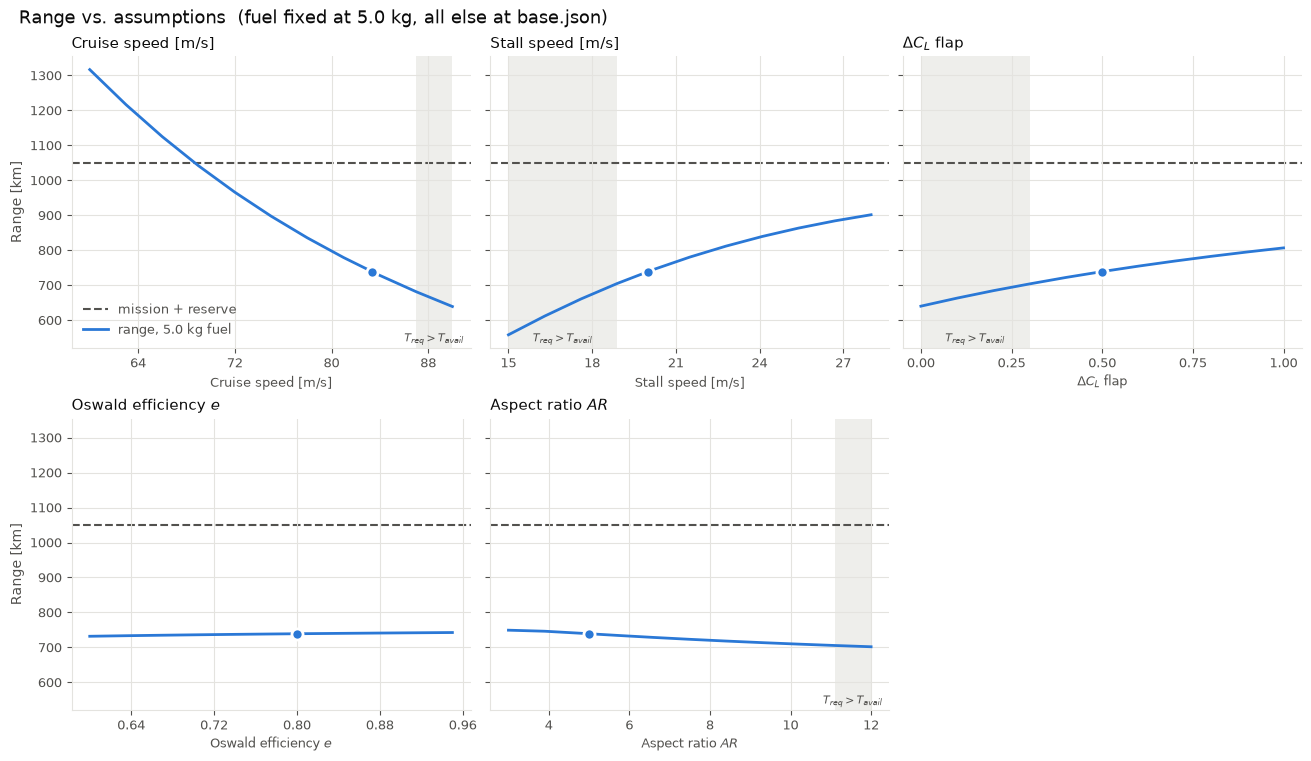

In [5]:
target_km = (base.mission.range + base.mission.reserve) / 1000

fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 3.75 * n_rows), sharey=True, constrained_layout=True)

for ax, (path, (label, *_)) in zip(axes.flat, SWEEPS.items()):
    df = results[path]

    bad = df.value[~df.range_power_ok]
    if len(bad):
        ax.axvspan(bad.min(), bad.max(), color=GRID, alpha=0.6, lw=0, zorder=0)
        ax.annotate("$T_{req} > T_{avail}$", (bad.mean(), 0.02), xycoords=("data", "axes fraction"),
                    ha="center", color=INK_MUTED, fontsize=8)

    ax.axhline(target_km, color=INK_MUTED, lw=1.5, ls="--", zorder=1, label="mission + reserve")
    ax.plot(df.value, df.range_km, color=SERIES, lw=2, zorder=2, label=f"range, {FUEL_MASS:.1f} kg fuel")
    ax.plot(get_value(base, path), range_base, "o", ms=8, color=SERIES, mec="white", mew=2, zorder=3)

    ax.set_title(label, color=INK, fontsize=11, loc="left")
    ax.set_xlabel(label, color=INK_MUTED, fontsize=9)
    ax.grid(color=GRID, lw=0.8)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    style(ax)

for ax in axes.flat[len(SWEEPS):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Range [km]", color=INK_MUTED)
axes.flat[0].legend(frameon=False, fontsize=9, labelcolor=INK_MUTED)

fig.suptitle(f"Range vs. assumptions  (fuel fixed at {FUEL_MASS:.1f} kg, all else at base.json)",
             color=INK, fontsize=13, x=0.01, ha="left")
plt.show()

### Which assumption matters most?

Elasticity at the baseline: **% change in required fuel per 1 % change in the parameter** (central difference, ±1 %). Lets you compare parameters with different units.

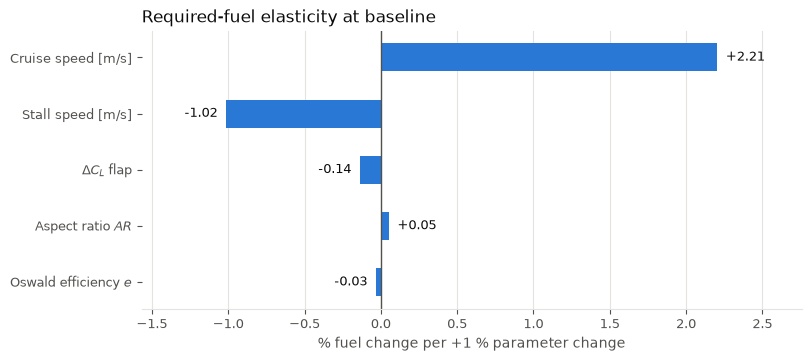

,elasticity
Cruise speed [m/s],2.206
Stall speed [m/s],-1.015
$\Delta C_{L}$ flap,-0.139
Aspect ratio $AR$,0.054
Oswald efficiency $e$,-0.034


In [6]:
STEP = 0.01

elasticity = {}
for path, (label, *_) in SWEEPS.items():
    x0 = get_value(base, path)
    f_up = get_fuel_kg(base.with_(**{path: x0 * (1 + STEP)}), abs_tol=1e-7)
    f_dn = get_fuel_kg(base.with_(**{path: x0 * (1 - STEP)}), abs_tol=1e-7)
    elasticity[label] = (f_up - f_dn) / fuel_base / (2 * STEP)

elasticity = pd.Series(elasticity).sort_values(key=np.abs)

fig, ax = plt.subplots(figsize=(8, 0.5 * len(elasticity) + 1), constrained_layout=True)
ax.barh(elasticity.index, elasticity.values, height=0.5, color=SERIES)
ax.axvline(0, color=INK_MUTED, lw=1)
for y, v in enumerate(elasticity.values):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(6 if v >= 0 else -6, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", color=INK, fontsize=9)
pad = 0.25 * np.abs(elasticity.values).max()
ax.set_xlim(min(elasticity.min(), 0) - pad, max(elasticity.max(), 0) + pad)
ax.set_xlabel("% fuel change per +1 % parameter change", color=INK_MUTED)
ax.set_title("Required-fuel elasticity at baseline", color=INK, loc="left")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
style(ax)
ax.spines["left"].set_visible(False)
plt.show()

elasticity.iloc[::-1].round(3).to_frame("elasticity")

## 2. Airfoil comparison

Each airfoil's data replaces the airfoil fields in `base.json`; everything else (flap $\Delta C_L$, $AR$, $e$) stays fixed. Each case runs the pipeline, so OpenVSP recomputes the parasite drag for the resized wing (the airfoil shape in the `.vsp3` itself isn't changed).

- **Take-off $c_{l,max}$** sizes the wing ($C_{L,max} \approx 0.9\,c_{l,max}$ + flap) and is the only airfoil value that changes the required fuel.
- **$c_{l,\alpha}$ and $\alpha_{0L}$** give the cruise angle of attack, i.e. the wing incidence.
- **Cruise $c_{l,max}$** is listed for reference (margin to stall in cruise).

**Fill in the `None` values** with polar data at your take-off Re (≈ 4·10⁵) and cruise Re (≈ 1.6·10⁶), e.g. from XFLR5. Rows with missing values are skipped. Note: in reality the flap $\Delta C_L$ and the wing's profile drag (`c_d_0_wing`) also differ per airfoil.

In [7]:
AIRFOILS = {
    "Current (base.json)": {
        "c_l_max_2d_takeoff":  base.assumptions.c_l_max_2d_takeoff,
        "c_l_max_2d_cruise":   base.assumptions.c_l_max_2d_cruise,
        "alpha_0_l_cruise":    base.assumptions.alpha_0_l_cruise,     # deg
        "c_l_alpha_2d_cruise": base.assumptions.c_l_alpha_2d_cruise,  # 1/deg
    },
    # TODO: fill in from XFLR5 / XFOIL at take-off and cruise Re
    "NACA 2412":  {"c_l_max_2d_takeoff": None, "c_l_max_2d_cruise": None, "alpha_0_l_cruise": None, "c_l_alpha_2d_cruise": None},
    "NACA 4412":  {"c_l_max_2d_takeoff": None, "c_l_max_2d_cruise": None, "alpha_0_l_cruise": None, "c_l_alpha_2d_cruise": None},
    "NACA 23012": {"c_l_max_2d_takeoff": None, "c_l_max_2d_cruise": None, "alpha_0_l_cruise": None, "c_l_alpha_2d_cruise": None},
    "Clark Y":    {"c_l_max_2d_takeoff": None, "c_l_max_2d_cruise": None, "alpha_0_l_cruise": None, "c_l_alpha_2d_cruise": None},
}

q_cruise = get_dynamic_pressure(v=base.mission.cruise_speed, rho=get_isa_density(altitude=FIELD_ALTITUDE + 120))
rows, missing = {}, []
for name, data in AIRFOILS.items():
    if any(v is None for v in data.values()):
        missing.append(name)
        continue
    b = base.with_(**{f"assumptions.{k}": v for k, v in data.items()})
    a = b.assumptions
    plane = try_pipeline(b)
    if plane is None:
        missing.append(f"{name} (mission not reachable)")
        continue

    mass = get_total_mass(fuel_mass=plane.fuel_mass)
    c_l = get_c_l_cruise(mass=mass, wing_area=plane.wing_area, q=q_cruise)  # start of cruise
    c_l_alpha = get_c_l_alpha_3d(c_l_alpha_2d=a.c_l_alpha_2d_cruise, aspect_ratio=a.wing_ar)

    rows[name] = {
        "fuel [kg]": float(plane.fuel_mass),
        "wing area [m²]": plane.wing_area,
        "span [m]": np.sqrt(plane.aspect_ratio * plane.wing_area),
        "C_D0": plane.c_d_0,
        "C_L,max take-off (incl. flap)": get_c_l_max_3d(c_l_max_2d=a.c_l_max_2d_takeoff) + a.delta_c_l_flap,
        "C_L cruise": c_l,
        "α cruise [deg]": get_alpha_cruise(c_l=c_l, c_l_alpha_3d=c_l_alpha, alpha_0_l=a.alpha_0_l_cruise),
        "C_L,max cruise / C_L cruise": get_c_l_max_3d(c_l_max_2d=a.c_l_max_2d_cruise) / c_l,
    }

airfoils = pd.DataFrame(rows).T.sort_values("fuel [kg]")
if missing:
    print("Skipped:", ", ".join(missing))
airfoils.round(3)

Skipped: NACA 2412, NACA 4412, NACA 23012, Clark Y


,fuel [kg],wing area [m²],span [m],C_D0,"C_L,max take-off (incl. flap)",C_L cruise,α cruise [deg],"C_L,max cruise / C_L cruise"
Current (base.json),7.506,0.493,1.57,0.021,1.823,0.106,-0.737,13.503


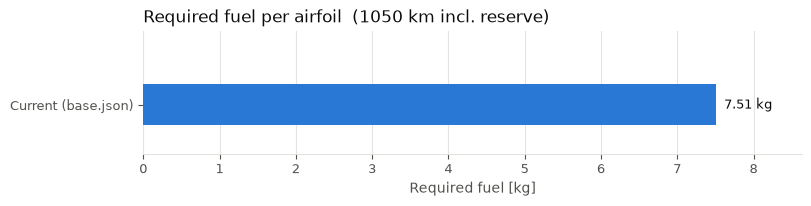

In [8]:
fig, ax = plt.subplots(figsize=(8, 0.55 * len(airfoils) + 1.4), constrained_layout=True)
order = airfoils["fuel [kg]"].sort_values(ascending=False)
ax.barh(order.index, order.values, height=0.5, color=SERIES, zorder=2)
for y, v in enumerate(order.values):
    ax.annotate(f"{v:.2f} kg", (v, y), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.set_xlim(0, order.max() * 1.15)
ax.set_ylim(-0.6, len(order) - 0.1)
ax.set_xlabel("Required fuel [kg]", color=INK_MUTED)
ax.set_title(f"Required fuel per airfoil  ({(base.mission.range + base.mission.reserve) / 1000:.0f} km incl. reserve)", color=INK, loc="left")
ax.grid(axis="x", color=GRID, lw=0.8, zorder=0)
style(ax)
ax.spines["left"].set_visible(False)
plt.show()